# Scenarios, weights and the non-linearity of ECL

**Question:** Why is the probability-weighted ECL of three macroeconomic scenarios larger than the ECL of the average scenario, by how much on a real book, and how much of the result depends on the weights the bank chooses?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- write the point-in-time PD as a function of a systematic factor and convert between a default rate and the factor it implies;
- show with numbers why the probability-weighted PD is not the PD of the average scenario, and why a "base" scenario at $z = 0$ is the median and not the mean;
- check the Gauss-Hermite integration over the factor and say how many nodes the engine's identity needs;
- weight the ECL of three scenarios by stage and read the weight sensitivity as an exact linear derivative while the staging is frozen;
- tell the two non-linearity indexes apart (the PD level and the ECL level) and measure what re-staging adds when the weights move.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "green", "amber": "amber", "red": "red"}
SCENARIO = {"baseline": "baseline", "adverse": "adverse", "severely-adverse": "severely adverse"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C06 at the reporting date 2008-12-31 (SBA 7(a) loans, U.S. Government Works, licence class `mirror-allowed`; the macroeconomic scenarios are shapes of the Federal Reserve's 2026 stress-test paths, mirror-allowed). One file is read, `data/derived/C06/rd-2008-12.json`:

- `outputs.scenarios`: three scenarios with their weight and their mean systematic factor $z$;
- `outputs.ecl_by_scenario`: the ECL of each scenario and stage, with the stages fixed at the weighted allocation;
- `outputs.weight_grid`: fifteen weight vectors on a grid of step 0.25, with the ECL **with the staging frozen** and the ECL **with the staging recomputed** at those weights;
- `outputs.non_linearity`: the PD-level and the ECL-level comparison of the weighted measure with the mean path, and the curve of the conditional PD against $z$.

The next cell loads the artifact and prints the scenarios, the weights and the engine versions.

In [2]:
# Load the reporting-date artifact and list its scenarios with their weights and factors
from riskvalidation.provisions import ecl as ecl_engine, term_structure as tsm
from riskvalidation.validation import ifrs9

LANG = "en"
ROOT = Path("../../..").resolve()
case = json.loads((ROOT / "data" / "derived" / "C06" / "rd-2008-12.json").read_text(encoding="utf-8"))
out = case["outputs"]
print("engine that baked the artifact:", case["provenance"]["riskvalidation_version"])
print("engine installed now:", md.version("riskvalidation"))
for s in out["scenarios"]:
    print(f"{SCENARIO[s['id']]:20s} | weight {s['weight']:.2f} | mean factor z {s['z_mean']:.4f}")
    print("   ", s["label"][LANG])

engine that baked the artifact: 1.0.1
engine installed now: 1.0.1
baseline             | weight 0.60 | mean factor z -1.4801
    Baseline (Fed 2026 shape)
adverse              | weight 0.30 | mean factor z -1.3735
    Adverse (midpoint of the Fed shapes, Contraste's own)
severely adverse     | weight 0.10 | mean factor z -1.3478
    Severely adverse (Fed 2026 shape)


## Method

IFRS 9 asks for an unbiased, probability-weighted amount (5.5.17(a)), built with more than one scenario when the loss is not linear in the macroeconomic path (B5.5.41 and B5.5.42; GPPC 2016, section 2.8.1.2). Three results carry this notebook.

**1. The conditional PD.** In the one-factor model of the IRB formula (BCBS 2005, section 4.2; Gordy 2003), an obligor defaults when its asset return, $\sqrt{\rho}\,Z + \sqrt{1-\rho}\,\varepsilon$, falls below $\Phi^{-1}(PD^{\mathrm{TTC}})$, with $Z$ and $\varepsilon$ standard normal and independent. The PD given the systematic factor $z$ is

$$PD^{\mathrm{PIT}}(z) = \Phi\!\left(\frac{\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{\rho}\,z}{\sqrt{1-\rho}}\right), \qquad \mathbb{E}_Z\bigl[PD^{\mathrm{PIT}}(Z)\bigr] = PD^{\mathrm{TTC}}$$

and its inverse gives the factor implied by an observed default rate $DR$: $z = \bigl(\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{1-\rho}\,\Phi^{-1}(DR)\bigr)/\sqrt{\rho}$. A negative $z$ is a bad year.

**2. The weighted measure and its non-linearity.**

$$\mathrm{ECL} = \sum_s w_s\,\mathrm{ECL}_s, \quad w_s \ge 0, \;\sum_s w_s = 1, \qquad \mathrm{NL} = \frac{\mathrm{ECL}_{\mathrm{weighted}}}{\mathrm{ECL}(\text{mean path})} - 1$$

Because $PD^{\mathrm{PIT}}$ is convex in $z$ over the usual range, Jensen's inequality gives $\mathbb{E}[PD(Z)] \ge PD(\mathbb{E}[Z])$: the weighted measure is at least the measure at the average scenario. The ECB (2024) criticises macro overlays built on the average path because they ignore this non-linearity and underestimate the mean impact.

**3. The weight sensitivity.** The ECL is linear in the weights, so moving weight from a reference scenario to $s$ changes it by $\partial\,\mathrm{ECL}/\partial w_s = \mathrm{ECL}_s - \mathrm{ECL}_{\mathrm{ref}}$ (BCBS d350, paragraph 36(a)). Staging is not linear in the weights when the SICR test uses weighted PDs (GPPC 2016, 2.7.2.10), so the engine's committed grid reports both versions: staging frozen (exactly linear) and staging recomputed.

The 100 per cent single-scenario ECLs are sensitivities, never the IFRS 9 measure.

### Step 1: the conditional PD curve of the book, and its inverse

The artifact gives the book's $PD^{\mathrm{TTC}}$ and $\rho$ (`non_linearity.parameters`) and the seven factors $z = -3, \dots, 3$ at which it reports the curve. The cell evaluates `ttc_to_pit` at those factors and then applies `implied_z`, the inverse, to the default rates the curve returned: the factors must come back. The figure draws the curve on a logarithmic axis with the seven points and the unconditional $PD^{\mathrm{TTC}}$.

PD_TTC: 0.016389 | rho: 0.12
z = -3 | PD(z): 0.121428 | factor recovered: -3.0
z = -2 | PD(z): 0.062128 | factor recovered: -2.0
z = -1 | PD(z): 0.028298 | factor recovered: -1.0
z = +0 | PD(z): 0.011432 | factor recovered: 0.0
z = +1 | PD(z): 0.004085 | factor recovered: 1.0
z = +2 | PD(z): 0.001288 | factor recovered: 2.0
z = +3 | PD(z): 0.000358 | factor recovered: 3.0


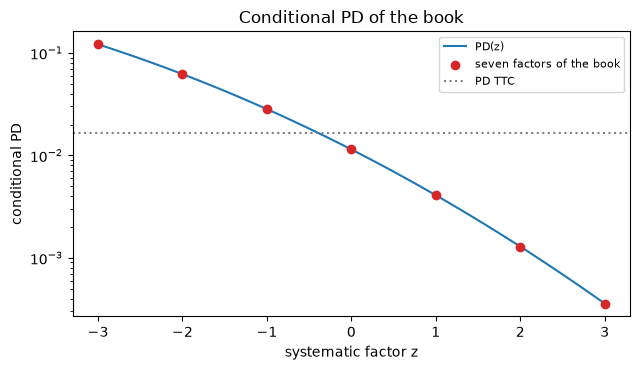

In [3]:
# Evaluate the conditional PD curve of the book at seven factors and recover the factors with the inverse
nl = out["non_linearity"]
pd_ttc, rho = nl["parameters"]["pd_ttc"], nl["parameters"]["rho"]
z_grid = np.array([p["z"] for p in nl["z_curve"]])
curve = tsm.ttc_to_pit(np.full(z_grid.size, pd_ttc), rho, z_grid)
recovered = tsm.implied_z(curve, pd_ttc, rho)
print("PD_TTC:", round(pd_ttc, 6), "| rho:", rho)
for z_, p_, r_ in zip(z_grid, curve, recovered):
    print("z =", f"{z_:+.0f}", "| PD(z):", round(float(p_), 6), "| factor recovered:", round(float(r_), 6))

zz = np.linspace(-3.0, 3.0, 121)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(zz, tsm.ttc_to_pit(np.full(zz.size, pd_ttc), rho, zz), color="tab:blue", label="PD(z)")
ax.scatter(z_grid, curve, color="tab:red", zorder=3, label="seven factors of the book")
ax.axhline(pd_ttc, color="grey", linestyle=":", label="PD TTC")
ax.set_yscale("log")
ax.set_xlabel("systematic factor z")
ax.set_ylabel("conditional PD")
ax.set_title("Conditional PD of the book")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The conditional PD falls from 12.14% at $z = -3$ to 0.04% at $z = +3$, a factor of more than 300 across six units of the factor, and the inverse returns the seven factors exactly. The curve is steep and bends: its slope is larger on the bad side, where $z$ is negative. A bad year raises the default rate far more than a good year lowers it, which is the shape that makes the average of the scenarios the wrong place to evaluate the loss.

### Step 2: a worked example of the non-linearity, and the median trap

The engine's reference example comes from the dossier's illustration: $PD^{\mathrm{TTC}} = 2\%$, $\rho = 0.12$, three scenarios at $z = +1$ (upside, weight 0.25), $z = 0$ (base, 0.50) and $z = -2$ (downside, 0.25). These are **inputs of the lesson**, chosen for the example, not Contraste data. The cell computes the conditional PD of each scenario, the weighted PD with `weighted_pit_pd`, the PD at the weighted mean factor, and the engine's own `nonlinearity_test`. The figure puts all of them on the curve.

conditional PD by scenario, percent: [0.526 1.429 7.342]
weighted PD, percent: 2.681 | weighted mean factor: -0.25
PD at that factor, percent: 1.8 | ratio: 1.49
engine test: index: 0.4898 | light: green
PD at z = 0 (the median), percent: 1.429


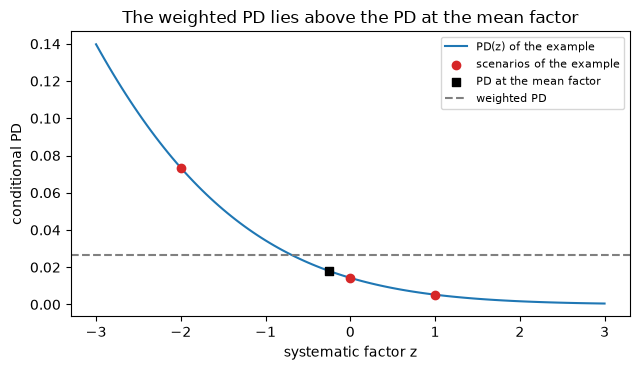

In [4]:
# The reference example: three scenarios, the weighted PD, the PD at the mean factor and the engine's test
EX_PD, EX_RHO = 0.02, 0.12  # inputs of the lesson
ex_z = np.array([1.0, 0.0, -2.0])
ex_w = np.array([0.25, 0.50, 0.25])
per_scenario = tsm.ttc_to_pit(EX_PD, EX_RHO, ex_z)
weighted = float(tsm.weighted_pit_pd(EX_PD, EX_RHO, ex_z, ex_w))
mean_z = float(np.sum(ex_w * ex_z))
at_mean = float(tsm.ttc_to_pit(EX_PD, EX_RHO, mean_z))
test = ifrs9.nonlinearity_test(EX_PD, EX_RHO, ex_z, ex_w, model_id="lesson")
print("conditional PD by scenario, percent:", np.round(100 * per_scenario, 3))
print("weighted PD, percent:", round(100 * weighted, 3), "| weighted mean factor:", mean_z)
print("PD at that factor, percent:", round(100 * at_mean, 3), "| ratio:", round(weighted / at_mean, 2))
print("engine test: index:", round(test.metric, 4), "| light:", LIGHT[test.light.value])
print("PD at z = 0 (the median), percent:", round(100 * float(per_scenario[1]), 3))

zz = np.linspace(-3.0, 3.0, 121)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(zz, tsm.ttc_to_pit(np.full(zz.size, EX_PD), EX_RHO, zz), color="tab:blue", label="PD(z) of the example")
ax.scatter(ex_z, per_scenario, color="tab:red", zorder=3, label="scenarios of the example")
ax.scatter([mean_z], [at_mean], color="black", marker="s", zorder=3, label="PD at the mean factor")
ax.axhline(weighted, color="grey", linestyle="--", label="weighted PD")
ax.set_xlabel("systematic factor z")
ax.set_ylabel("conditional PD")
ax.set_title("The weighted PD lies above the PD at the mean factor")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The weighted PD is 2.681% and the PD at the average scenario, $z = -0.25$, is 1.800%: ignoring the non-linearity understates the PD by a third, a ratio of 1.49, and the loss rate with a loss given default of 40% would be 1.07% weighted against 0.72% at the mean. The base scenario at $z = 0$ gives 1.429%, which is the median and not the mean, and it sits below the unconditional 2%. A bank that calls the median scenario its base case and stops there reports less than the weighted measure IFRS 9 asks for.

### Step 3: the Gauss-Hermite check

The identity $\mathbb{E}_Z[PD^{\mathrm{PIT}}(Z)] = PD^{\mathrm{TTC}}$ is the engine's cross-check of the non-linearity. `gauss_hermite_pit_pd` integrates the conditional PD over the standard normal with probabilists' Gauss-Hermite nodes. The cell raises the number of nodes from 2 to 64 and draws the error against $PD^{\mathrm{TTC}}$, floored at $10^{-16}$, the rounding of the arithmetic.

nodes   2 | error against PD_TTC: 2e-04
nodes   4 | error against PD_TTC: 5e-07
nodes   8 | error against PD_TTC: 9e-12
nodes  16 | error against PD_TTC: 1e-16
nodes  32 | error against PD_TTC: 1e-16
nodes  64 | error against PD_TTC: 1e-16


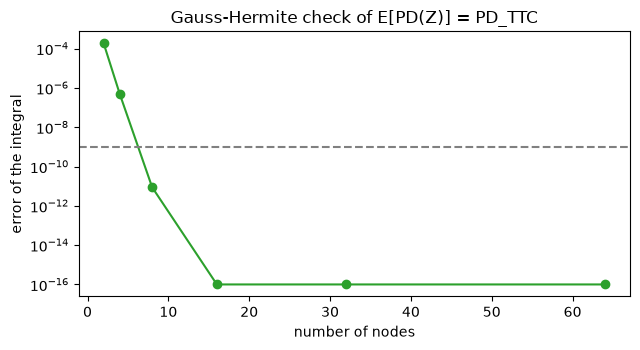

In [5]:
# The error of the Gauss-Hermite integral against PD_TTC as the nodes grow, floored at 1e-16
nodes = (2, 4, 8, 16, 32, 64)
integrals = [tsm.gauss_hermite_pit_pd(EX_PD, EX_RHO, n) for n in nodes]
errors = [max(abs(value - EX_PD), 1e-16) for value in integrals]
for n, error in zip(nodes, errors):
    print("nodes", f"{n:3d}", "| error against PD_TTC:", f"{error:.0e}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.semilogy(nodes, errors, marker="o", color="tab:green")
ax.axhline(1e-9, color="grey", linestyle="--")
ax.set_xlabel("number of nodes")
ax.set_ylabel("error of the integral")
ax.set_title("Gauss-Hermite check of E[PD(Z)] = PD_TTC")
fig.tight_layout()
plt.show()

The error falls from 2e-04 with two nodes to 5e-07 with four and 9e-12 with eight, and from 16 nodes on it is at the floor of the arithmetic. The dashed line marks $10^{-9}$, the tolerance of the engine's test, which eight nodes already satisfy. The integral is therefore an exact enough check that the conditional PD, averaged over the factor, gives back the through-the-cycle PD: the curve of step 1 is a calibrated map from the factor to the default rate.

### Step 4: the same two comparisons on the committed book

Back to C06. The artifact gives the three scenario factors and weights it used (`scenario_points`). The cell computes the weighted PD and the PD at the weighted mean factor of the book with `weighted_pit_pd` and `ttc_to_pit`, and the PD-level index with `non_linearity_index`. It then reads the **ECL level**: the committed ECL weighted over the scenarios and the committed ECL at the mean path go through the same function, and the figure sets the two indexes side by side.

weighted PD of the book: 0.04045198
PD at the mean factor of the book: 0.04041987
PD-level index: 0.000794 | ECL-level index: 0.02121
the ECL-level index over the PD-level index: 26.7


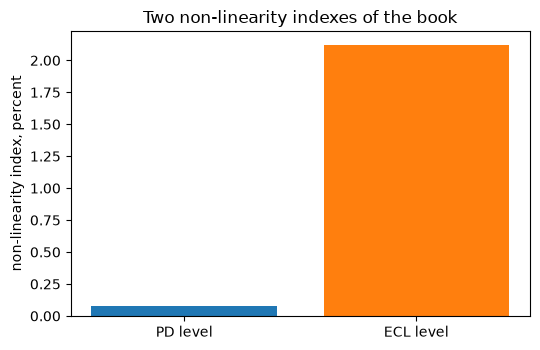

In [6]:
# Compute the weighted PD and the PD at the mean factor of the book, and the two indexes
points = nl["scenario_points"]
z_book = np.array([p["z"] for p in points])
w_book = np.array([p["weight"] for p in points])
pd_weighted = float(tsm.weighted_pit_pd(pd_ttc, rho, z_book, w_book))
pd_mean = float(tsm.ttc_to_pit(pd_ttc, rho, float(np.sum(w_book * z_book))))
pd_index = ecl_engine.non_linearity_index(pd_weighted, pd_mean)
ecl_index = ecl_engine.non_linearity_index(nl["ecl_weighted"], nl["ecl_at_mean_path"])
print("weighted PD of the book:", round(pd_weighted, 8))
print("PD at the mean factor of the book:", round(pd_mean, 8))
print("PD-level index:", round(pd_index, 6), "| ECL-level index:", round(ecl_index, 6))
print("the ECL-level index over the PD-level index:", round(ecl_index / pd_index, 1))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(["PD level", "ECL level"], [100 * pd_index, 100 * ecl_index], color=["tab:blue", "tab:orange"])
ax.set_ylabel("non-linearity index, percent")
ax.set_title("Two non-linearity indexes of the book")
fig.tight_layout()
plt.show()

At the PD level the book's three scenarios are close together on the curve (factors between -1.48 and -1.35), so the weighted PD of 0.04045 exceeds the PD at the mean factor by only 0.08%. At the ECL level the index is 0.0212, 2.12%, about 27 times larger. The ECL is more non-linear than the PD because the staging moves with the scenario: a worse scenario puts more loans in Stage 2, where the lifetime ECL is several times larger. A validator who tested only the PD level would pass a measure whose real non-linearity sits one level up.

### Step 5: weighting the scenario ECLs by stage

`ecl_by_scenario` holds the ECL of each scenario by stage, with the stages fixed at the weighted allocation. We stack the three scenarios into an array of shape (scenarios, stages) and weight it with `probability_weighted_ecl`, which returns the allowance by stage. Summing the rows gives the ECL at 100% of each scenario, a sensitivity and never the IFRS 9 measure. The figure sets the three single-scenario totals against the weighted total and the ECL at the mean path.

Stage 1 | weighted ECL, USD millions: 798.078
Stage 2 | weighted ECL, USD millions: 68.929
Stage 3 | weighted ECL, USD millions: 0.0
baseline             ECL at 100 percent of the scenario, USD millions:   897.476
adverse              ECL at 100 percent of the scenario, USD millions:   825.460
severely adverse     ECL at 100 percent of the scenario, USD millions:   808.827
weighted total, USD millions: 867.007
ECL at the mean path, USD millions: 848.999


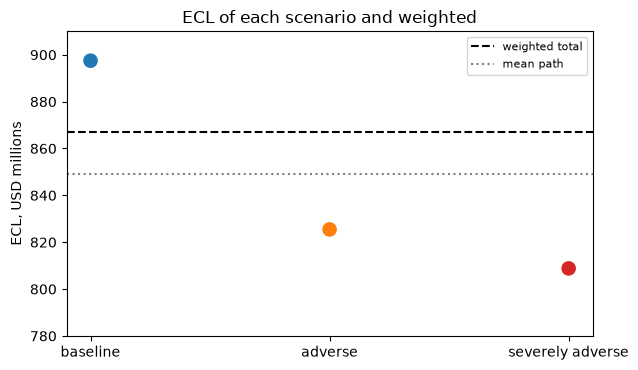

In [7]:
# Weight the ECL of the three scenarios by stage and compare the scenarios with the weighted total
ids = [s["id"] for s in out["scenarios"]]
weights = np.array([s["weight"] for s in out["scenarios"]])
stages = ("stage1", "stage2", "stage3")
by = {(r["scenario_id"], r["stage"]): r["ecl"] for r in out["ecl_by_scenario"]["rows"]}
matrix = np.array([[by[(sid, st)] for st in stages] for sid in ids])
weighted_by_stage = ecl_engine.probability_weighted_ecl(matrix, weights)
single = matrix.sum(axis=1)
total = float(weighted_by_stage.sum())
for k, value in enumerate(weighted_by_stage, start=1):
    print("Stage", k, "| weighted ECL, USD millions:", round(float(value) / 1e6, 3))
for sid, value in zip(ids, single):
    print(f"{SCENARIO[sid]:20s} ECL at 100 percent of the scenario, USD millions: {value / 1e6:9.3f}")
print("weighted total, USD millions:", round(total / 1e6, 3))
print("ECL at the mean path, USD millions:", round(nl["ecl_at_mean_path"] / 1e6, 3))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.scatter([SCENARIO[s] for s in ids], single / 1e6, s=90, color=["tab:blue", "tab:orange", "tab:red"], zorder=3)
ax.axhline(total / 1e6, color="black", linestyle="--", label="weighted total")
ax.axhline(nl["ecl_at_mean_path"] / 1e6, color="grey", linestyle=":", label="mean path")
ax.set_ylim(780, 910)
ax.set_ylabel("ECL, USD millions")
ax.set_title("ECL of each scenario and weighted")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The weighted allowance is 867.007 million USD, almost all of it in Stage 1 (798.078 million) with 68.929 million in Stage 2, and it lies above the 848.999 million of the mean path, as the non-linearity says it should. The figure shows something else that a validator reads first: the severely adverse scenario produces a lower ECL, 808.827 million, than the baseline, 897.476 million. This is the committed finding `F-SCENARIO-ORDER`, a wrong sign in the hazard's macro sensitivities at this date, and any sensitivity built on the ordering of the scenarios inherits it.

### Step 6: the weight sensitivity, linear when the staging is frozen

With the stages fixed the ECL is linear in the weights, so `weight_sensitivity` returns the exact change of moving all the weight to each scenario from a reference, $\mathrm{ECL}_s - \mathrm{ECL}_{\mathrm{ref}}$. The artifact keeps fifteen weight vectors on a grid of step 0.25, with the ECL recomputed after re-staging at those weights. The cell weights the single-scenario totals at each of them with `probability_weighted_ecl`, which is the frozen-staging ECL, and sets it beside the committed recomputed one along one edge of the grid.

weight vectors on the grid: 15
change of moving all weight from the baseline to each scenario, USD millions:
[  0.    -72.016 -88.65 ]
recomputed minus frozen ECL on the grid, USD millions, smallest and largest:
-15.235 2.089
Stage 2 share, recomputed, smallest and largest:
0.00779 0.01236


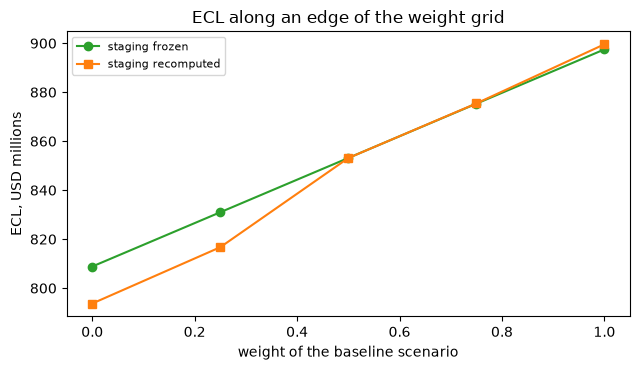

In [8]:
# Weight the single-scenario totals on the weight grid and read the sensitivity
grid = out["weight_grid"]["points"]
frozen = np.array([float(ecl_engine.probability_weighted_ecl(single, np.array(p["weights"]))) for p in grid])
sens = ecl_engine.weight_sensitivity(single, 0)
gap = np.array([p["ecl_recomputed"] - p["ecl_frozen"] for p in grid]) / 1e6
shares = [p["stage2_ratio_recomputed"] for p in grid]
print("weight vectors on the grid:", len(grid))
print("change of moving all weight from the baseline to each scenario, USD millions:")
print(np.round(sens / 1e6, 3))
print("recomputed minus frozen ECL on the grid, USD millions, smallest and largest:")
print(round(float(gap.min()), 3), round(float(gap.max()), 3))
print("Stage 2 share, recomputed, smallest and largest:")
print(round(min(shares), 5), round(max(shares), 5))

edge = [k for k, p in enumerate(grid) if p["weights"][1] == 0.0]
edge = [edge[j] for j in np.argsort([grid[k]["weights"][0] for k in edge])]
xs = [grid[k]["weights"][0] for k in edge]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(xs, [frozen[k] / 1e6 for k in edge], marker="o", color="tab:green", label="staging frozen")
recomputed = [grid[k]["ecl_recomputed"] / 1e6 for k in edge]
ax.plot(xs, recomputed, marker="s", color="tab:orange", label="staging recomputed")
ax.set_xlabel("weight of the baseline scenario")
ax.set_ylabel("ECL, USD millions")
ax.set_title("ECL along an edge of the weight grid")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Moving all the weight from the baseline to the adverse scenario changes the frozen ECL by -72.016 million and to the severely adverse by -88.650 million, both negative because of the scenario order found in step 5. The two lines of the figure are parallel but not equal: re-staging at the new weights changes the ECL by between -15.235 and +2.089 million relative to the frozen value, and moves the Stage 2 share between 0.78% and 1.24%. A linear reading of the weights is exact only while the stages stand still, and the part it misses is the part the validator must show.

## Results

**Answer:** The probability-weighted ECL of the book is 867.007 million USD against 848.999 million at the average path, an excess of 2.12%, an index of 0.0212 that is about 27 times the 0.0008 its PD alone shows, because the conditional PD is convex in the macroeconomic factor and the staging moves with the scenario; the result also depends on the weights, since moving all of them from the baseline to the adverse scenario changes the ECL by -72.016 million, while re-staging adds between -15.235 and 2.089 million that a linear reading misses.

- **The curve and its inverse close.** The conditional PD of the book runs from 12.14% at $z = -3$ to 0.04% at $z = +3$, and `implied_z` recovers the seven factors from the default rates the curve returned.
- **The weighted PD is not the PD of the average scenario.** In the lesson example the weighted PD is 2.681% and the PD at the average factor is 1.800%, a ratio of 1.49; the base scenario at $z = 0$ gives 1.429%, the median, below the unconditional 2%.
- **The identity needs few nodes.** The Gauss-Hermite error against $PD^{\mathrm{TTC}}$ is 9e-12 with eight nodes and at the floor of the arithmetic from sixteen, so the engine's tolerance of $10^{-9}$ is met with room to spare.
- **The ECL level is where the non-linearity sits.** On the book the PD-level index is 0.0008 and the ECL-level index is 0.0212, because a worse scenario also puts more loans in Stage 2.
- **The committed scenarios are not ordered by severity.** The severely adverse scenario gives 808.827 million and the baseline 897.476 million (finding `F-SCENARIO-ORDER`), so the weight sensitivities are negative, -72.016 and -88.650 million, and a validator reads that as a model finding first.
- **Frozen and recomputed staging differ.** Along the weight grid the recomputed ECL differs from the frozen one by -15.235 to 2.089 million and the Stage 2 share moves between 0.78% and 1.24%.

What this notebook does not show: the scenario factors of the book sit close together (between -1.48 and -1.35), so the PD-level non-linearity of the book is small by construction. The three scenarios are shapes of the Federal Reserve's 2026 paths, not forecasts of 2008. The wrong sign of the macro sensitivities is a finding to fix in the model, and this notebook only measures its consequence.

## Summary

- The conditional PD is a convex function of the systematic factor over the usual range, so the probability-weighted PD is at least the PD at the average scenario; the engine states the identity, its inverse and a Gauss-Hermite check.
- A base scenario at $z = 0$ gives the median PD, not the mean; the example shows 1.429% against 2.000%.
- The ECL is weighted scenario by scenario with `probability_weighted_ecl`, and the ECL-level and PD-level indexes are different quantities: the first is larger because the staging moves with the scenario.
- With the staging frozen the weight sensitivity is exactly $\mathrm{ECL}_s - \mathrm{ECL}_{\mathrm{ref}}$; re-staging at the new weights adds a part that a linear reading misses.
- The committed scenarios are not ordered by severity at this date (finding `F-SCENARIO-ORDER`); a validator reads that as a model finding before reading any sensitivity.

**What to try next.** Change `EX_RHO` to 0.04 and to 0.24 and watch the ratio of the weighted PD to the PD at the mean factor; change `ex_w` to equal weights. Then continue with notebook 04, which turns these ECLs into an allowance and reconciles its movement.

## References

- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 June 2016, sections 2.1.1, 2.7.2 and 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm
- BCBS (2005), An explanatory note on the Basel II IRB risk weight functions, section 4.2: the one-factor model. https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), 199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, July 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf